In [1]:
import os
from pathlib import Path
root = Path.cwd()
while not (root / ".git").exists():
    root = root.parent
os.chdir(root)
print(os.getcwd())

import numpy as np, pandas as pd, mne
import matplotlib.pyplot as plt
import seaborn as sns
mne.set_log_level("ERROR")
os.makedirs("results/figures", exist_ok=True)

COL = {"C": "#0072B2", "F": "#E69F00", "A": "#CC79A7"}
NAME = {"C": "CN", "F": "FTD", "A": "AD"}
ORDER = ["C", "F", "A"]
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("data/ds004504/participants.tsv", sep="\t")
gm = pd.read_csv("results/tables/graph_metrics.csv")
spec = pd.read_csv("results/tables/spectral_features.csv")
stats = pd.read_csv("results/tables/group_stats.csv")

c:\Users\Alive\Documents\eeg-brain-networks-dementia


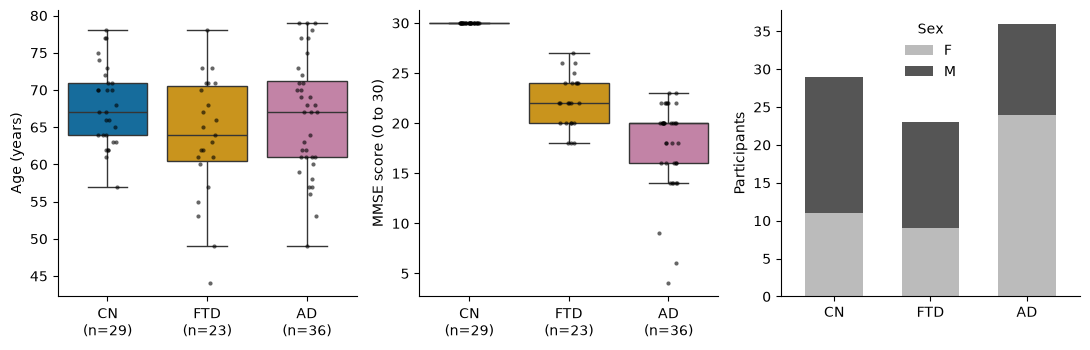

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.6))
for a, col, lab in [(ax[0], "Age", "Age (years)"), (ax[1], "MMSE", "MMSE score (0 to 30)")]:
    sns.boxplot(data=df, x="Group", y=col, hue="Group", order=ORDER, hue_order=ORDER,
                palette=COL, legend=False, showfliers=False, ax=a)
    sns.stripplot(data=df, x="Group", y=col, order=ORDER, color="black", size=3, alpha=0.6, ax=a)
    a.set_xticks(range(3)); a.set_xticklabels([f"{NAME[g]}\n(n={int((df.Group == g).sum())})" for g in ORDER])
    a.set_xlabel(""); a.set_ylabel(lab)
ct = pd.crosstab(df.Group, df.Gender).loc[ORDER]
ct.plot.bar(stacked=True, ax=ax[2], color=["#BBBBBB", "#555555"], rot=0, width=0.6)
ax[2].set_xticklabels([NAME[g] for g in ORDER]); ax[2].set_xlabel(""); ax[2].set_ylabel("Participants")
ax[2].legend(title="Sex", frameon=False)
plt.tight_layout()
plt.savefig("results/figures/fig1_cohort_summary.png", dpi=200)
plt.show()

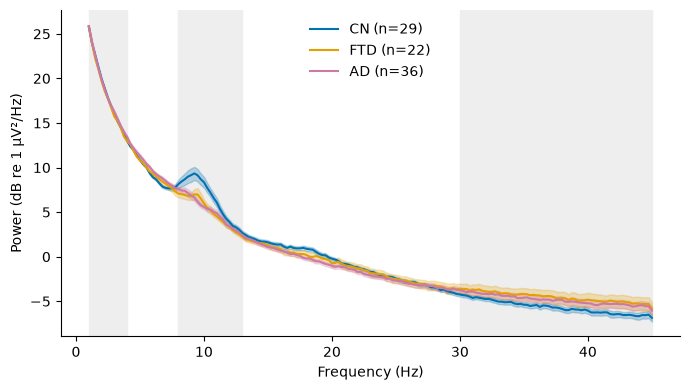

In [3]:
psd = []
for sub in spec.participant_id:
    ep = mne.read_epochs(f"data/epochs/{sub}-epo.fif", preload=True, verbose=False)
    p, freqs = ep.compute_psd(method="welch", fmin=1, fmax=45, verbose=False).get_data(return_freqs=True)
    psd.append(10 * np.log10(p.mean(axis=(0, 1)) * 1e12))        # V^2/Hz -> uV^2/Hz, in dB
psd = np.array(psd)
grp = spec.Group.values

fig, ax = plt.subplots(figsize=(7, 4))
for lo, hi in [(1, 4), (8, 13), (30, 45)]:
    ax.axvspan(lo, hi, color="#EEEEEE", zorder=0)
for g in ORDER:
    m = psd[grp == g]
    mean, sem = m.mean(axis=0), m.std(axis=0, ddof=1) / np.sqrt(len(m))
    ax.plot(freqs, mean, color=COL[g], label=f"{NAME[g]} (n={len(m)})")
    ax.fill_between(freqs, mean - sem, mean + sem, color=COL[g], alpha=0.25)
ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Power (dB re 1 µV²/Hz)")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("results/figures/fig2_mean_spectrum.png", dpi=200)
plt.show()

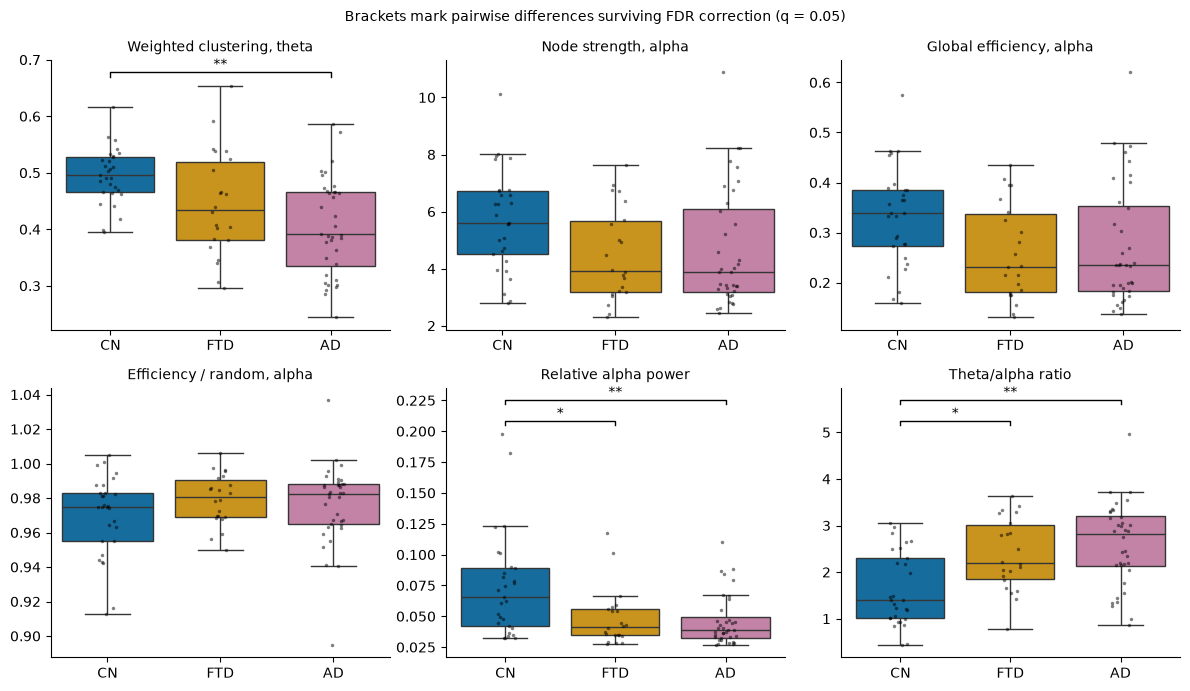

In [4]:
wide = gm.pivot(index="participant_id", columns="band", values=["clustering", "strength", "efficiency", "e_norm"])
wide.columns = [f"{m}_{b}" for m, b in wide.columns]
wide = wide.join(spec.set_index("participant_id")[["relpow_alpha", "theta_alpha_ratio", "Group"]])

PANELS = [("clustering_theta", "clustering", "theta", "Weighted clustering, theta"),
          ("strength_alpha", "strength", "alpha", "Node strength, alpha"),
          ("efficiency_alpha", "efficiency", "alpha", "Global efficiency, alpha"),
          ("e_norm_alpha", "e_norm", "alpha", "Efficiency / random, alpha"),
          ("relpow_alpha", "relpow_alpha", "spectral", "Relative alpha power"),
          ("theta_alpha_ratio", "theta_alpha_ratio", "spectral", "Theta/alpha ratio")]
PAIRS = [("C", "F", "F-C"), ("C", "A", "A-C"), ("F", "A", "A-F")]

def stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (col, metric, band, title) in zip(axes.ravel(), PANELS):
    sns.boxplot(data=wide, x="Group", y=col, hue="Group", order=ORDER, hue_order=ORDER,
                palette=COL, legend=False, showfliers=False, ax=ax)
    sns.stripplot(data=wide, x="Group", y=col, order=ORDER, color="black", size=2.5, alpha=0.5, ax=ax)
    ax.set_xticks(range(3)); ax.set_xticklabels([NAME[g] for g in ORDER])
    ax.set_xlabel(""); ax.set_ylabel(""); ax.set_title(title, fontsize=10)
    top = wide[col].max(); rng = wide[col].max() - wide[col].min()
    h = 0
    for g1, g2, key in PAIRS:
        row = stats[(stats.metric == metric) & (stats.band == band) & (stats.pair == key)]
        if len(row) and row.p_fdr.iloc[0] < 0.05:
            i1, i2 = ORDER.index(g1), ORDER.index(g2)
            y = top + rng * (0.06 + 0.10 * h); h += 1
            ax.plot([i1, i1, i2, i2], [y - rng * 0.02, y, y, y - rng * 0.02], color="black", lw=1)
            ax.text((i1 + i2) / 2, y, stars(row.p_fdr.iloc[0]), ha="center", va="bottom")
plt.suptitle("Brackets mark pairwise differences surviving FDR correction (q = 0.05)", fontsize=10)
plt.tight_layout()
plt.savefig("results/figures/fig5_key_measures.png", dpi=200)
plt.show()

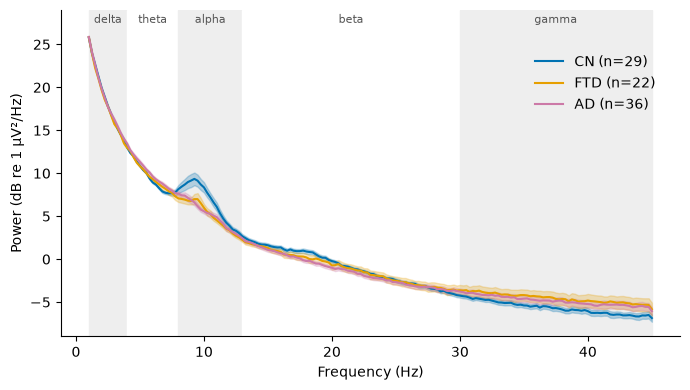

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for lo, hi, lab in [(1, 4, "delta"), (4, 8, "theta"), (8, 13, "alpha"), (13, 30, "beta"), (30, 45, "gamma")]:
    ax.axvspan(lo, hi, color="#EEEEEE" if lab in ("delta", "alpha", "gamma") else "white", zorder=0)
    ax.text((lo + hi) / 2, 27.5, lab, ha="center", fontsize=8, color="#555555")
for g in ORDER:
    m = psd[grp == g]
    mean, sem = m.mean(axis=0), m.std(axis=0, ddof=1) / np.sqrt(len(m))
    ax.plot(freqs, mean, color=COL[g], label=f"{NAME[g]} (n={len(m)})")
    ax.fill_between(freqs, mean - sem, mean + sem, color=COL[g], alpha=0.25)
ax.set_ylim(-9, 29)
ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Power (dB re 1 µV²/Hz)")
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(0.98, 0.9))
plt.tight_layout()
plt.savefig("results/figures/fig2_mean_spectrum.png", dpi=200)
plt.show()

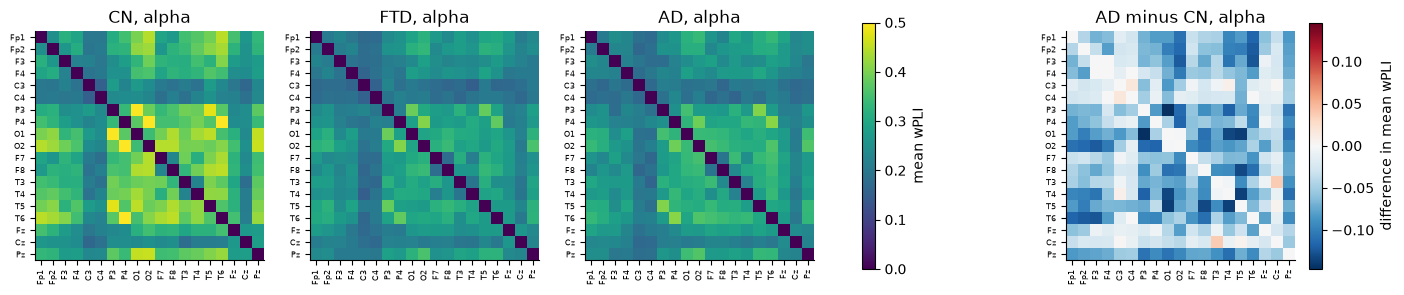

In [6]:
iu = np.triu_indices(19, k=1)
ch_names = mne.read_epochs("data/epochs/sub-001-epo.fif", verbose=False).ch_names

def group_mean(g, band=2):
    subs = spec.loc[spec.Group == g, "participant_id"]
    return np.mean([np.load(f"data/connectivity/{s}_wpli.npy")[band] for s in subs], axis=0)

M = {g: group_mean(g) for g in ORDER}
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, g in zip(axes[:3], ORDER):
    im = ax.imshow(M[g], vmin=0, vmax=0.5, cmap="viridis"); ax.set_title(f"{NAME[g]}, alpha")
fig.colorbar(im, ax=axes[:3], shrink=0.8, label="mean wPLI")
diff = M["A"] - M["C"]; lim = np.abs(diff).max()
im2 = axes[3].imshow(diff, vmin=-lim, vmax=lim, cmap="RdBu_r"); axes[3].set_title("AD minus CN, alpha")
fig.colorbar(im2, ax=axes[3], shrink=0.8, label="difference in mean wPLI")
for ax in axes:
    ax.set_xticks(range(19)); ax.set_yticks(range(19))
    ax.set_xticklabels(ch_names, rotation=90, fontsize=6); ax.set_yticklabels(ch_names, fontsize=6)
plt.savefig("results/figures/fig3_group_wpli_alpha.png", dpi=200, bbox_inches="tight")
plt.show()

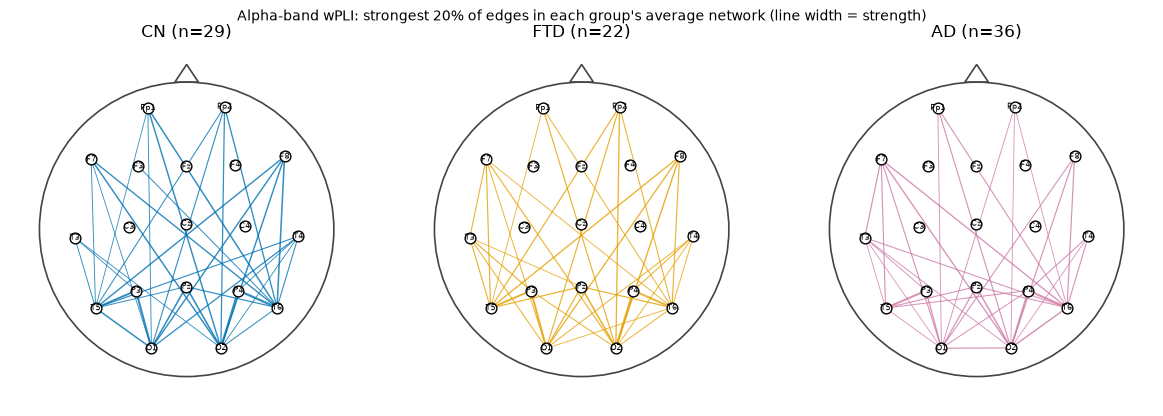

In [7]:
from matplotlib.patches import Circle, Polygon
ep0 = mne.read_epochs("data/epochs/sub-001-epo.fif", verbose=False)
layout = mne.channels.make_eeg_layout(ep0.info)
pos_by_name = {n: p[:2] for n, p in zip(layout.names, layout.pos)}
pos = np.array([pos_by_name[c] for c in ch_names])
center = pos.mean(axis=0); radius = np.abs(pos - center).max() * 1.2

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, g in zip(axes, ORDER):
    Mg = M[g]; thr = np.quantile(Mg[iu], 0.8)
    ax.add_patch(Circle(center, radius, fill=False, color="#444444", lw=1.2))
    ax.add_patch(Polygon([center + [-0.08 * radius, radius], center + [0.08 * radius, radius],
                          center + [0, radius * 1.12]], fill=False, color="#444444", lw=1.2))
    for i, j in zip(*iu):
        if Mg[i, j] >= thr:
            ax.plot(*zip(pos[i], pos[j]), color=COL[g], lw=0.6 + 9 * (Mg[i, j] - thr), alpha=0.8)
    ax.scatter(pos[:, 0], pos[:, 1], s=60, color="white", edgecolor="black", zorder=3)
    for c, (x, y) in zip(ch_names, pos):
        ax.text(x, y, c, ha="center", va="center", fontsize=5.5, zorder=4)
    ax.set_title(f"{NAME[g]} (n={int((spec.Group == g).sum())})")
    ax.set_xlim(center[0] - radius * 1.2, center[0] + radius * 1.2)
    ax.set_ylim(center[1] - radius * 1.2, center[1] + radius * 1.25)
    ax.set_aspect("equal"); ax.axis("off")
plt.suptitle("Alpha-band wPLI: strongest 20% of edges in each group's average network (line width = strength)", fontsize=10)
plt.tight_layout()
plt.savefig("results/figures/fig4_alpha_networks.png", dpi=200)
plt.show()

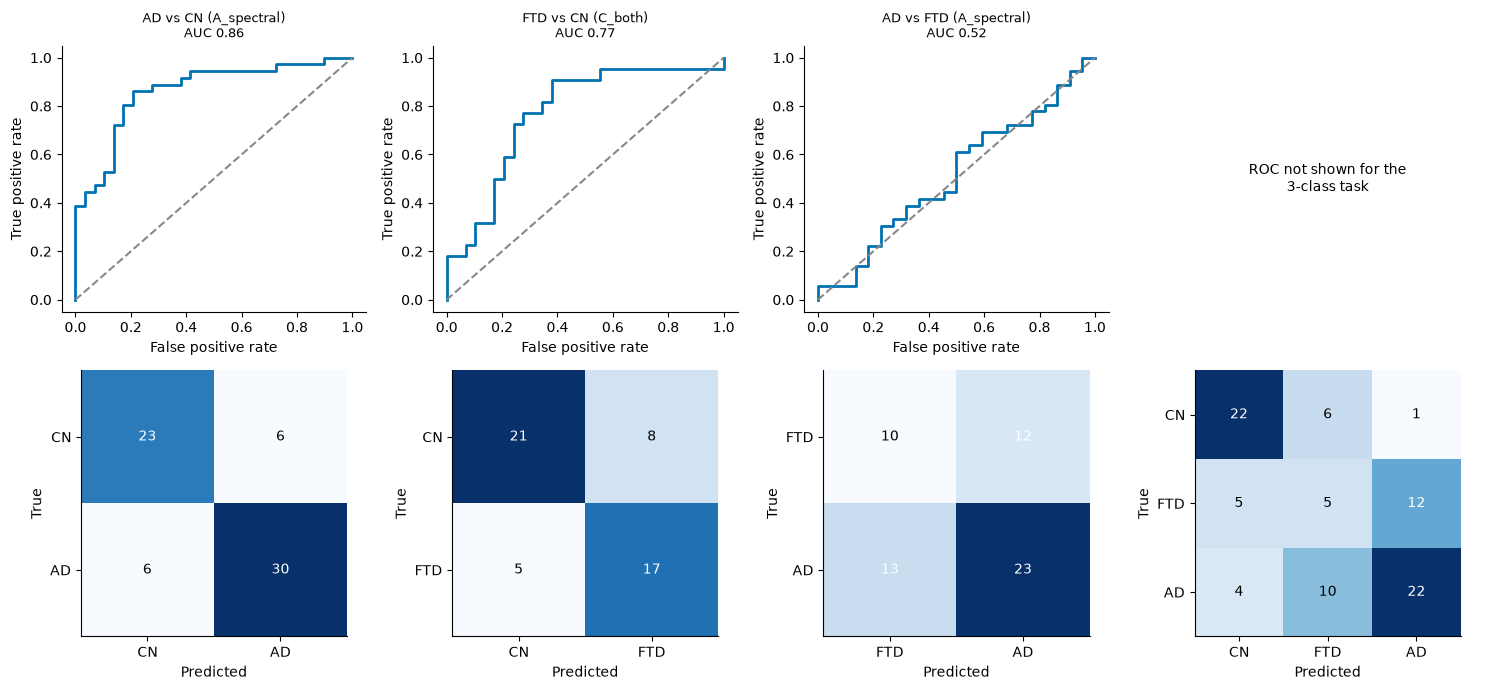

In [8]:
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
pr = pd.read_csv("results/tables/loso_predictions_logistic.csv")
res = pd.read_csv("results/tables/classification_results_logistic.csv")
cand = res[res.features != "age_only"]
best = cand.loc[cand.groupby("task").balanced_accuracy.idxmax()].set_index("task")
LAB = {"AD_vs_CN": ("CN", "AD"), "FTD_vs_CN": ("CN", "FTD"), "AD_vs_FTD": ("FTD", "AD")}

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for k, task in enumerate(["AD_vs_CN", "FTD_vs_CN", "AD_vs_FTD", "3class"]):
    f = best.loc[task, "features"]
    d = pr[(pr.task == task) & (pr.features == f)]
    ax_roc, ax_cm = axes[0, k], axes[1, k]
    if task != "3class":
        y = d["true"].astype(int).values
        fpr, tpr, _ = roc_curve(y, d["proba_1"].values)
        ax_roc.plot(fpr, tpr, color="#0072B2", lw=2)
        ax_roc.plot([0, 1], [0, 1], "--", color="#888888")
        ax_roc.set_title(f"{task.replace('_', ' ')} ({f})\nAUC {roc_auc_score(y, d['proba_1']):.2f}", fontsize=9)
        ax_roc.set_xlabel("False positive rate"); ax_roc.set_ylabel("True positive rate")
        cm = confusion_matrix(y, d["pred"].astype(int).values); labels = LAB[task]
    else:
        ax_roc.axis("off"); ax_roc.text(0.5, 0.5, "ROC not shown for the\n3-class task", ha="center", va="center")
        order = ["C", "F", "A"]
        cm = confusion_matrix(d["true"], d["pred"], labels=order); labels = [NAME[g] for g in order]
    ax_cm.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax_cm.text(j, i, int(v), ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
    ax_cm.set_xticks(range(len(labels))); ax_cm.set_yticks(range(len(labels)))
    ax_cm.set_xticklabels(labels); ax_cm.set_yticklabels(labels)
    ax_cm.set_xlabel("Predicted"); ax_cm.set_ylabel("True")
plt.tight_layout()
plt.savefig("results/figures/fig7_roc_confusion.png", dpi=200)
plt.show()

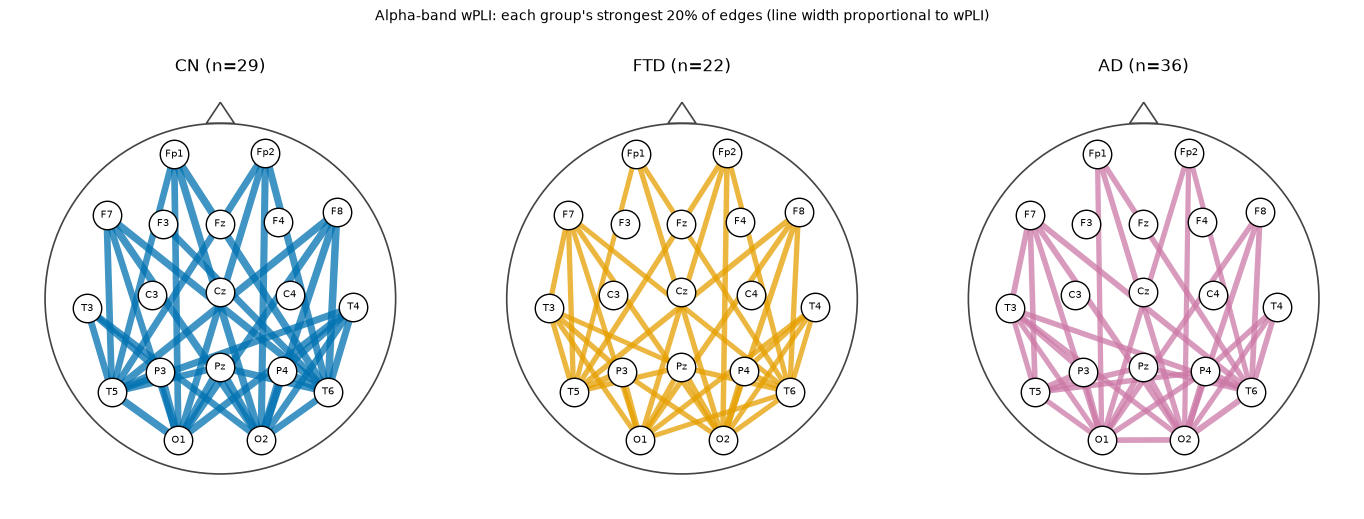

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5.2))
for ax, g in zip(axes, ORDER):
    Mg = M[g]; thr = np.quantile(Mg[iu], 0.8)
    ax.add_patch(Circle(center, radius, fill=False, color="#444444", lw=1.2))
    ax.add_patch(Polygon([center + [-0.08 * radius, radius], center + [0.08 * radius, radius],
                          center + [0, radius * 1.12]], fill=False, color="#444444", lw=1.2))
    for i, j in zip(*iu):
        if Mg[i, j] >= thr:
            ax.plot(*zip(pos[i], pos[j]), color=COL[g], lw=12 * Mg[i, j], alpha=0.75, zorder=1)
    ax.scatter(pos[:, 0], pos[:, 1], s=420, color="white", edgecolor="black", zorder=3)
    for c, (x, y) in zip(ch_names, pos):
        ax.text(x, y, c, ha="center", va="center", fontsize=7, zorder=4)
    ax.set_title(f"{NAME[g]} (n={int((spec.Group == g).sum())})")
    ax.set_xlim(center[0] - radius * 1.2, center[0] + radius * 1.2)
    ax.set_ylim(center[1] - radius * 1.2, center[1] + radius * 1.25)
    ax.set_aspect("equal"); ax.axis("off")
fig.suptitle("Alpha-band wPLI: each group's strongest 20% of edges (line width proportional to wPLI)", y=0.99, fontsize=10)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig("results/figures/fig4_alpha_networks.png", dpi=200)
plt.show()

In [10]:
color="white" if v > 0.6 * cm.max() else "black"

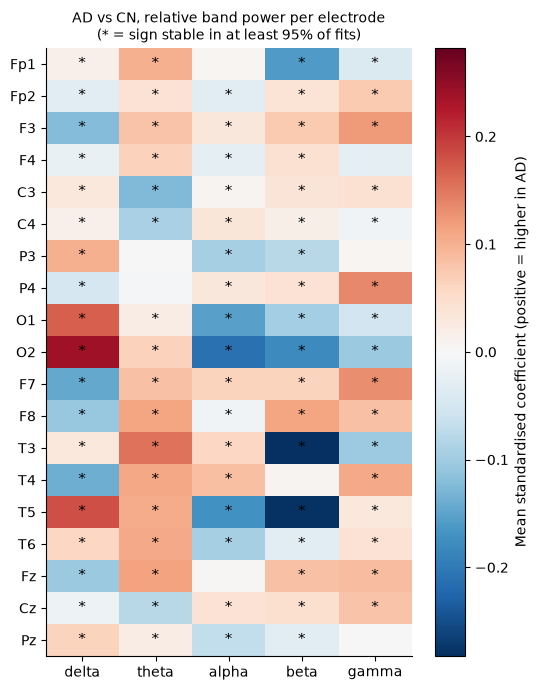

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut

chan = pd.read_csv("results/tables/spectral_features_channels.csv").set_index("participant_id")
grp_by = df.set_index("participant_id")["Group"]
ids = [s for s in chan.index if grp_by[s] in ("A", "C")]
X = chan.loc[ids].drop(columns="Group")
y = (grp_by.loc[ids] == "A").astype(int).values
BANDS5 = ["delta", "theta", "alpha", "beta", "gamma"]

coefs = []
for tr, _ in LeaveOneOut().split(X):
    pipe = Pipeline([("s", StandardScaler()),
                     ("c", LogisticRegression(C=0.1, max_iter=5000, class_weight="balanced"))])
    pipe.fit(X.values[tr], y[tr])
    coefs.append(pipe.named_steps["c"].coef_[0])
coefs = np.array(coefs)
mean_c = coefs.mean(axis=0)
consistent = (np.sign(coefs) == np.sign(mean_c)).mean(axis=0) >= 0.95
cols = list(X.columns)
H = np.array([[mean_c[cols.index(f"{b}_{ch}")] for b in BANDS5] for ch in ch_names])
S = np.array([[consistent[cols.index(f"{b}_{ch}")] for b in BANDS5] for ch in ch_names])

fig, ax = plt.subplots(figsize=(5.5, 7))
lim = np.abs(H).max()
im = ax.imshow(H, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        if S[i, j]:
            ax.text(j, i, "*", ha="center", va="center", fontsize=11)
ax.set_xticks(range(5)); ax.set_xticklabels(BANDS5)
ax.set_yticks(range(19)); ax.set_yticklabels(ch_names)
fig.colorbar(im, ax=ax, label="Mean standardised coefficient (positive = higher in AD)")
ax.set_title("AD vs CN, relative band power per electrode\n(* = sign stable in at least 95% of fits)", fontsize=10)
plt.tight_layout()
plt.savefig("results/figures/fig8_feature_weights.png", dpi=200)
plt.show()

Stable cells: 34 of 95


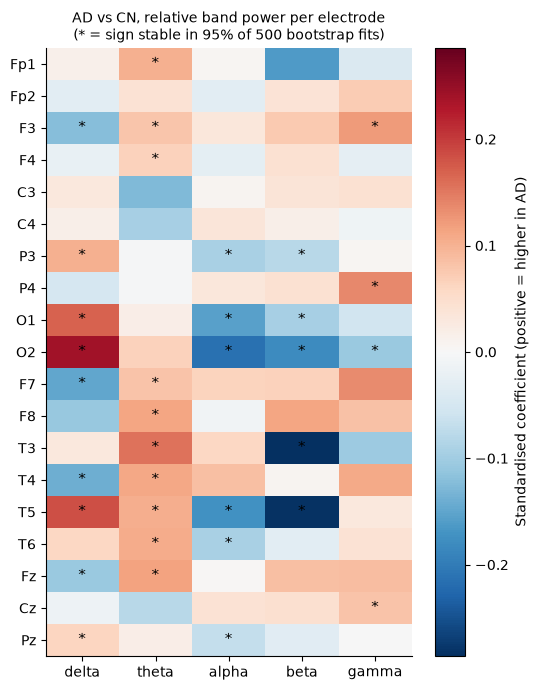

In [12]:
rng = np.random.default_rng(0)
n = len(y)

def fit_coef(Xv, yv):
    pipe = Pipeline([("s", StandardScaler()),
                     ("c", LogisticRegression(C=0.1, max_iter=5000, class_weight="balanced"))])
    pipe.fit(Xv, yv)
    return pipe.named_steps["c"].coef_[0]

full = fit_coef(X.values, y)
boot = []
while len(boot) < 500:
    idx = rng.integers(0, n, n)
    if len(np.unique(y[idx])) < 2:
        continue
    boot.append(fit_coef(X.values[idx], y[idx]))
boot = np.array(boot)
stable = (np.sign(boot) == np.sign(full)).mean(axis=0) >= 0.95

H = np.array([[full[cols.index(f"{b}_{ch}")] for b in BANDS5] for ch in ch_names])
S = np.array([[stable[cols.index(f"{b}_{ch}")] for b in BANDS5] for ch in ch_names])
print("Stable cells:", int(S.sum()), "of", S.size)

fig, ax = plt.subplots(figsize=(5.5, 7))
lim = np.abs(H).max()
im = ax.imshow(H, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        if S[i, j]:
            ax.text(j, i, "*", ha="center", va="center", fontsize=11)
ax.set_xticks(range(5)); ax.set_xticklabels(BANDS5)
ax.set_yticks(range(19)); ax.set_yticklabels(ch_names)
fig.colorbar(im, ax=ax, label="Standardised coefficient (positive = higher in AD)")
ax.set_title("AD vs CN, relative band power per electrode\n(* = sign stable in 95% of 500 bootstrap fits)", fontsize=10)
plt.tight_layout()
plt.savefig("results/figures/fig8_feature_weights.png", dpi=200)
plt.show()

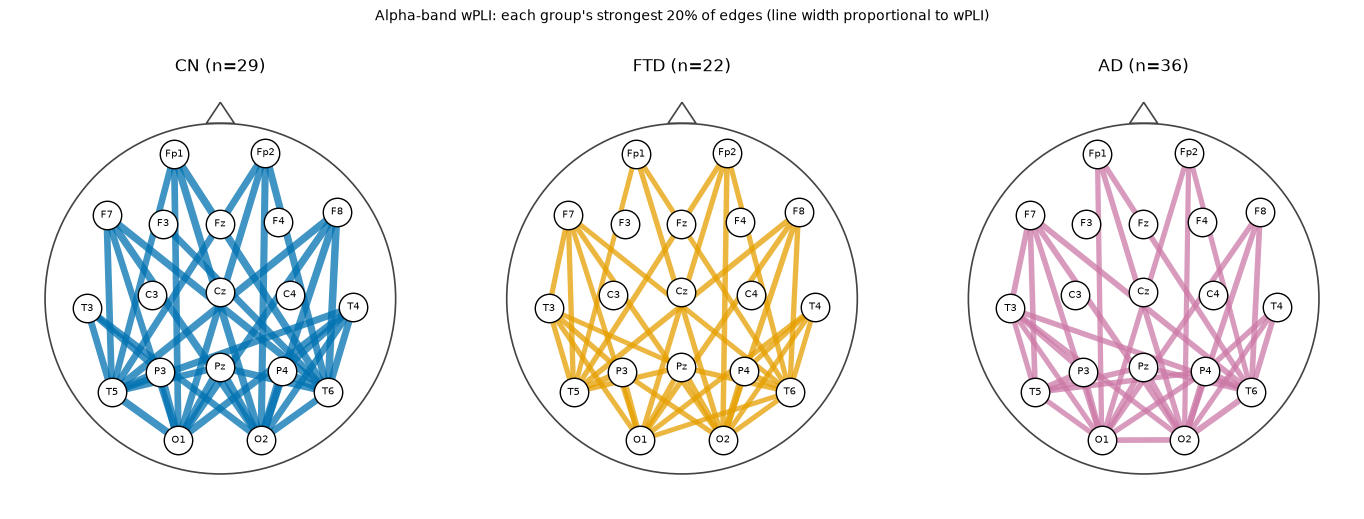

In [16]:
from matplotlib.patches import Circle, Polygon

iu = np.triu_indices(19, k=1)
ep0 = mne.read_epochs("data/epochs/sub-001-epo.fif", verbose=False)
ch_names = ep0.ch_names
layout = mne.channels.make_eeg_layout(ep0.info)
pos_by_name = {n: p[:2] for n, p in zip(layout.names, layout.pos)}
pos = np.array([pos_by_name[c] for c in ch_names])
center = pos.mean(axis=0); radius = np.abs(pos - center).max() * 1.2
M = {g: np.mean([np.load(f"data/connectivity/{s}_wpli.npy")[2]
                 for s in spec.loc[spec.Group == g, "participant_id"]], axis=0) for g in ORDER}

fig, axes = plt.subplots(1, 3, figsize=(14, 5.2))
for ax, g in zip(axes, ORDER):
    Mg = M[g]; thr = np.quantile(Mg[iu], 0.8)
    ax.add_patch(Circle(center, radius, fill=False, color="#444444", lw=1.2))
    ax.add_patch(Polygon([center + [-0.08 * radius, radius], center + [0.08 * radius, radius],
                          center + [0, radius * 1.12]], fill=False, color="#444444", lw=1.2))
    for i, j in zip(*iu):
        if Mg[i, j] >= thr:
            ax.plot(*zip(pos[i], pos[j]), color=COL[g], lw=12 * Mg[i, j], alpha=0.75, zorder=1)
    ax.scatter(pos[:, 0], pos[:, 1], s=420, color="white", edgecolor="black", zorder=3)
    for c, (x, y) in zip(ch_names, pos):
        ax.text(x, y, c, ha="center", va="center", fontsize=7, zorder=4)
    ax.set_title(f"{NAME[g]} (n={int((spec.Group == g).sum())})")
    ax.set_xlim(center[0] - radius * 1.2, center[0] + radius * 1.2)
    ax.set_ylim(center[1] - radius * 1.2, center[1] + radius * 1.25)
    ax.set_aspect("equal"); ax.axis("off")
fig.suptitle("Alpha-band wPLI: each group's strongest 20% of edges (line width proportional to wPLI)", y=0.99, fontsize=10)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig("results/figures/fig4_alpha_networks.png", dpi=200)
plt.show()

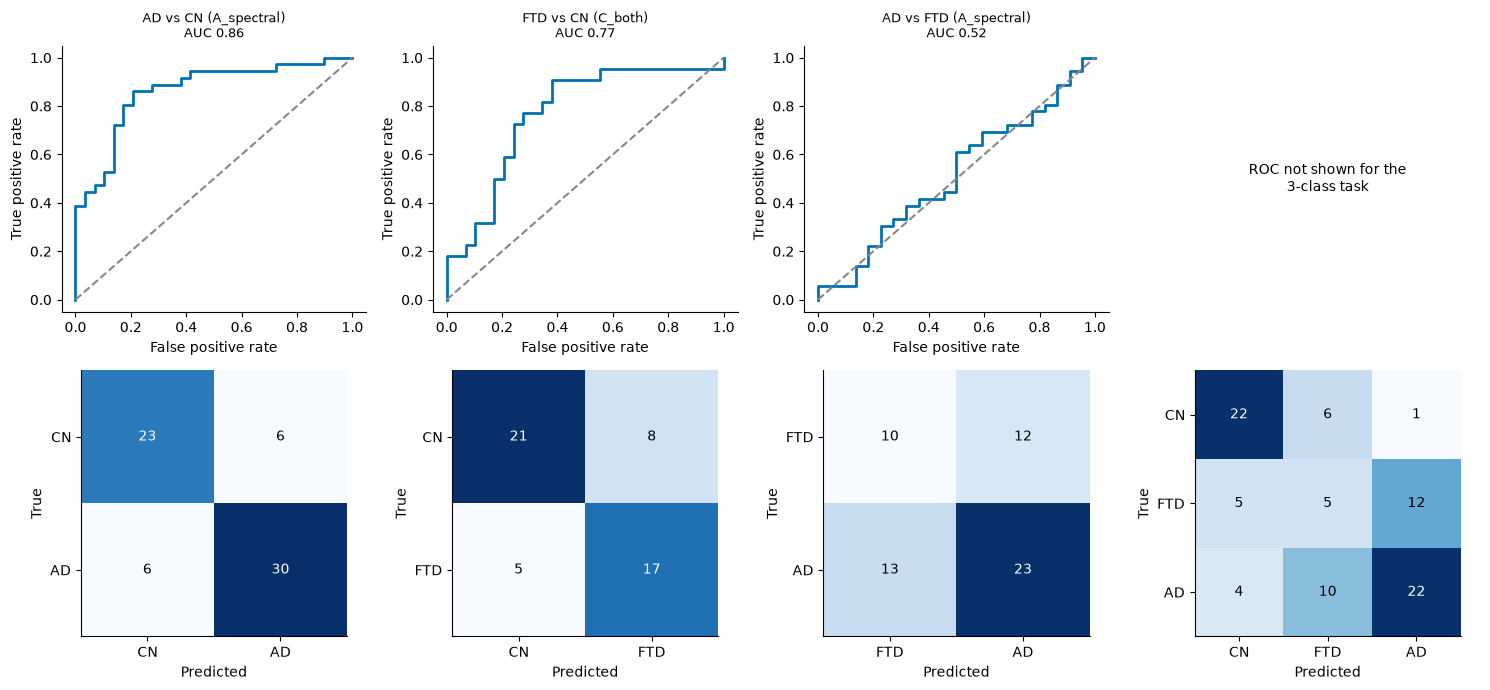

In [17]:
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

pr = pd.read_csv("results/tables/loso_predictions_logistic.csv")
res = pd.read_csv("results/tables/classification_results_logistic.csv")
cand = res[res.features != "age_only"]
best = cand.loc[cand.groupby("task").balanced_accuracy.idxmax()].set_index("task")
LAB = {"AD_vs_CN": ("CN", "AD"), "FTD_vs_CN": ("CN", "FTD"), "AD_vs_FTD": ("FTD", "AD")}

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for k, task in enumerate(["AD_vs_CN", "FTD_vs_CN", "AD_vs_FTD", "3class"]):
    f = best.loc[task, "features"]
    d = pr[(pr.task == task) & (pr.features == f)]
    ax_roc, ax_cm = axes[0, k], axes[1, k]
    if task != "3class":
        y = d["true"].astype(int).values
        fpr, tpr, _ = roc_curve(y, d["proba_1"].values)
        ax_roc.plot(fpr, tpr, color="#0072B2", lw=2)
        ax_roc.plot([0, 1], [0, 1], "--", color="#888888")
        ax_roc.set_title(f"{task.replace('_', ' ')} ({f})\nAUC {roc_auc_score(y, d['proba_1']):.2f}", fontsize=9)
        ax_roc.set_xlabel("False positive rate"); ax_roc.set_ylabel("True positive rate")
        cm = confusion_matrix(y, d["pred"].astype(int).values); labels = LAB[task]
    else:
        ax_roc.axis("off"); ax_roc.text(0.5, 0.5, "ROC not shown for the\n3-class task", ha="center", va="center")
        order = ["C", "F", "A"]
        cm = confusion_matrix(d["true"], d["pred"], labels=order); labels = [NAME[g] for g in order]
    ax_cm.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax_cm.text(j, i, int(v), ha="center", va="center", color="white" if v > 0.6 * cm.max() else "black")
    ax_cm.set_xticks(range(len(labels))); ax_cm.set_yticks(range(len(labels)))
    ax_cm.set_xticklabels(labels); ax_cm.set_yticklabels(labels)
    ax_cm.set_xlabel("Predicted"); ax_cm.set_ylabel("True")
plt.tight_layout()
plt.savefig("results/figures/fig7_roc_confusion.png", dpi=200)
plt.show()

In [18]:
import sys
sys.path.append("src")
import graphs
import networkx as nx
from scipy.stats import mannwhitneyu

drop = [ch_names.index(c) for c in ["Fp1", "Fp2", "F7", "F8"]]
keep = [i for i in range(19) if i not in drop]
rows = []
for sub in spec.participant_id:
    Wall = np.load(f"data/connectivity/{sub}_wpli.npy")
    for b, band in [(1, "theta"), (2, "alpha")]:
        W = Wall[b][np.ix_(keep, keep)]
        G = graphs._prep(W)
        L, E = graphs._path_and_eff(G)
        rows.append(dict(participant_id=sub, band=band, efficiency=E,
                         clustering=nx.average_clustering(G, weight="weight"),
                         strength=float(np.mean([d for _, d in G.degree(weight="weight")]))))
sens = pd.DataFrame(rows).merge(spec[["participant_id", "Group"]], on="participant_id")

out = []
for band in ["theta", "alpha"]:
    d = sens[sens.band == band]
    for metric in ["strength", "clustering", "efficiency"]:
        for g1, g2 in [("A", "C"), ("F", "C"), ("A", "F")]:
            x = d.loc[d.Group == g1, metric]; y = d.loc[d.Group == g2, metric]
            U, p = mannwhitneyu(x, y, alternative="two-sided")
            out.append(dict(band=band, metric=metric, pair=f"{g1}-{g2}", median1=x.median(),
                            median2=y.median(), r_rb=2 * U / (len(x) * len(y)) - 1, p_uncorrected=p))
sens_res = pd.DataFrame(out)
sens_res.to_csv("results/tables/sensitivity_no_frontal_pole.csv", index=False)
print(sens_res.round(4).to_string(index=False))

 band     metric pair  median1  median2    r_rb  p_uncorrected
theta   strength  A-C   2.5810   2.2177  0.2912         0.0456
theta   strength  F-C   2.4666   2.2177  0.1975         0.2346
theta   strength  A-F   2.5810   2.4666  0.1212         0.4465
theta clustering  A-C   0.4339   0.5096 -0.6207         0.0000
theta clustering  F-C   0.4481   0.5096 -0.3887         0.0188
theta clustering  A-F   0.4339   0.4481 -0.2626         0.0972
theta efficiency  A-C   0.1955   0.1648  0.3238         0.0262
theta efficiency  F-C   0.1840   0.1648  0.2069         0.2129
theta efficiency  A-F   0.1955   0.1840  0.1515         0.3403
alpha   strength  A-C   3.0642   4.3385 -0.4061         0.0053
alpha   strength  F-C   3.1370   4.3385 -0.4232         0.0105
alpha   strength  A-F   3.0642   3.1370 -0.0126         0.9425
alpha clustering  A-C   0.4152   0.4490 -0.1226         0.4020
alpha clustering  F-C   0.4213   0.4490 -0.1003         0.5491
alpha clustering  A-F   0.4152   0.4213 -0.0556        

In [19]:
cmp = stats[(stats.family == "primary_graph") & stats.metric.isin(["strength", "clustering", "efficiency"])
            & stats.band.isin(["alpha", "theta"])]
print(cmp[["metric", "band", "pair", "r_rb", "p", "p_fdr"]].round(4).to_string(index=False))


    metric  band pair    r_rb      p  p_fdr
clustering theta  A-C -0.6379 0.0000 0.0010
clustering theta  F-C -0.3699 0.0254 0.1717
efficiency alpha  A-C -0.3487 0.0166 0.1717
efficiency alpha  F-C -0.3730 0.0242 0.1717
  strength alpha  A-C -0.3525 0.0155 0.1717
  strength alpha  F-C -0.3762 0.0230 0.1717
efficiency theta  A-C  0.3142 0.0310 0.1857
  strength theta  A-C  0.2663 0.0676 0.2645
clustering alpha  F-C -0.2351 0.1565 0.4402
clustering theta  A-F -0.2146 0.1757 0.4792
efficiency theta  F-C  0.2069 0.2129 0.5331
clustering alpha  A-C -0.1609 0.2705 0.5661
  strength theta  F-C  0.1850 0.2659 0.5661
efficiency theta  A-F  0.1465 0.3568 0.6749
  strength theta  A-F  0.1389 0.3825 0.6749
clustering alpha  A-F  0.0404 0.8038 0.9745
efficiency alpha  A-F  0.0429 0.7915 0.9745
  strength alpha  A-F  0.0152 0.9298 0.9936
